# HW 2 — Part A: Agent-Based Epidemic Spread

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

N_AGENTS = 200
GRID_SIZE = 20
N_STEPS = 300
N_RUNS = 20

S, I, R = 0, 1, 2
STATE_NAMES = ["Susceptible", "Infected", "Recovered"]
COLORS = ["C0", "C3", "C2"]
DIRECTIONS = np.array([[0, 0], [-1, 0], [1, 0], [0, -1], [0, 1]]) # actions: [stay, left, right, down, up]

In [2]:

# Deterministic SIR reference for comparison with ABM, generated by GPT
def simulate_sir(p, q, n_steps=N_STEPS, substeps=10):
    beta = p / (GRID_SIZE ** 2)
    gamma = q
    dt = 1.0 / substeps

    history = np.zeros((n_steps + 1, 3), dtype=float)
    current = np.array([N_AGENTS - 5, 5, 0], dtype=float)
    history[0] = current

    for step in range(1, n_steps + 1):
        for _ in range(substeps):
            s, i, r = current

            new_infections = beta * s * i
            new_recoveries = gamma * i

            derivatives = np.array([
                -new_infections,
                new_infections - new_recoveries,
                new_recoveries
            ])

            current = current + dt * derivatives

        history[step] = current

    return history


## A-ii / A-iii: Agent behaviors and Simulations

In [3]:
def simulate_abm(p: float, q: float, seed: int, n_steps: int = N_STEPS):
    rng = np.random.default_rng(seed)

    # Init agent positions
    positions = rng.integers(0, GRID_SIZE, size=(N_AGENTS, 2))

    # Init agent states
    states = np.full(N_AGENTS, S, dtype=np.int8)
    initial_infected = rng.choice(N_AGENTS, size=5, replace=False)
    states[initial_infected] = I

    # Init history record to record past states
    history = np.zeros((n_steps + 1, 3), dtype=int)
    history[0] = np.bincount(states, minlength=3)# t = 0

    for t in range(1, n_steps + 1):
        # Move toward a direction
        chosen = rng.integers(0, len(DIRECTIONS), size=N_AGENTS)
        positions = np.clip(positions + DIRECTIONS[chosen], 0, GRID_SIZE - 1)

        # Transmission
        cell_ids = positions[:, 0] * GRID_SIZE + positions[:, 1]
        infected_per_cell = np.bincount(cell_ids[states == I], minlength=GRID_SIZE * GRID_SIZE)
        at_risk = (states == S) & (infected_per_cell[cell_ids] > 0)
        new_infections = at_risk & (rng.random(N_AGENTS) < p)

        # Recover
        new_recoveries = (states == I) & (rng.random(N_AGENTS) < q)

        # Record updates
        states[new_recoveries] = R
        states[new_infections] = I
        history[t] = np.bincount(states, minlength=3)

    return history


## A-iii: Simulation

Final (S, I, R)= [  2   1 197]


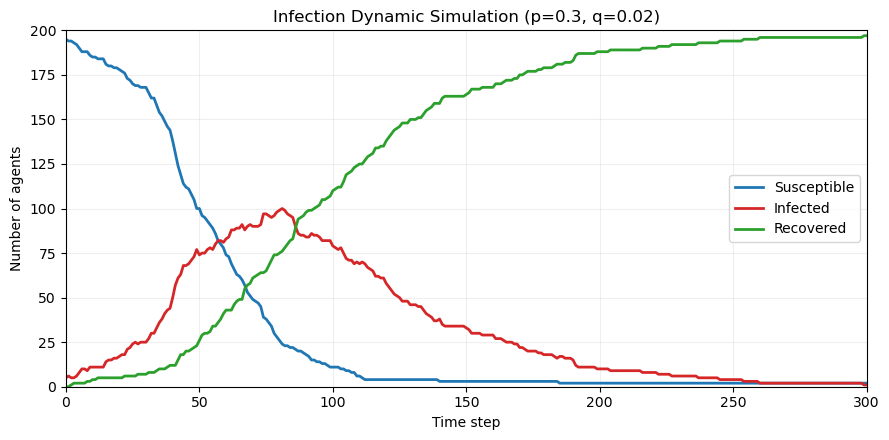

In [4]:
trial = simulate_abm(p=0.3, q=0.02, seed=7)
print("Final (S, I, R)=", trial[-1])

t = np.arange(N_STEPS + 1)
fig, ax = plt.subplots(figsize=(9, 4.5))
for state in (S, I, R):
    ax.plot(
        t, trial[:, state], label=STATE_NAMES[state],
        color=COLORS[state], linewidth=2
    )

ax.set(
    xlabel="Time step", ylabel="Number of agents",
    title="Infection Dynamic Simulation (p=0.3, q=0.02)",
    xlim=(0, N_STEPS), ylim=(0, N_AGENTS)
)

ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## A-iv: Sensitivity Analysis

In [5]:
P_VALUES = [0.15, 0.30]
Q_VALUES = [0.02, 0.04]
SEEDS = list(range(407, 407 + N_RUNS))

runs = {}
for p in P_VALUES:
    for q in Q_VALUES:
        runs[(p, q)] = np.stack([simulate_abm(p, q, seed) for seed in SEEDS])
        print(f"p={p:.2f}, q={q:.2f}: {runs[(p, q)].shape}")

p=0.15, q=0.02: (20, 301, 3)
p=0.15, q=0.04: (20, 301, 3)
p=0.30, q=0.02: (20, 301, 3)
p=0.30, q=0.04: (20, 301, 3)


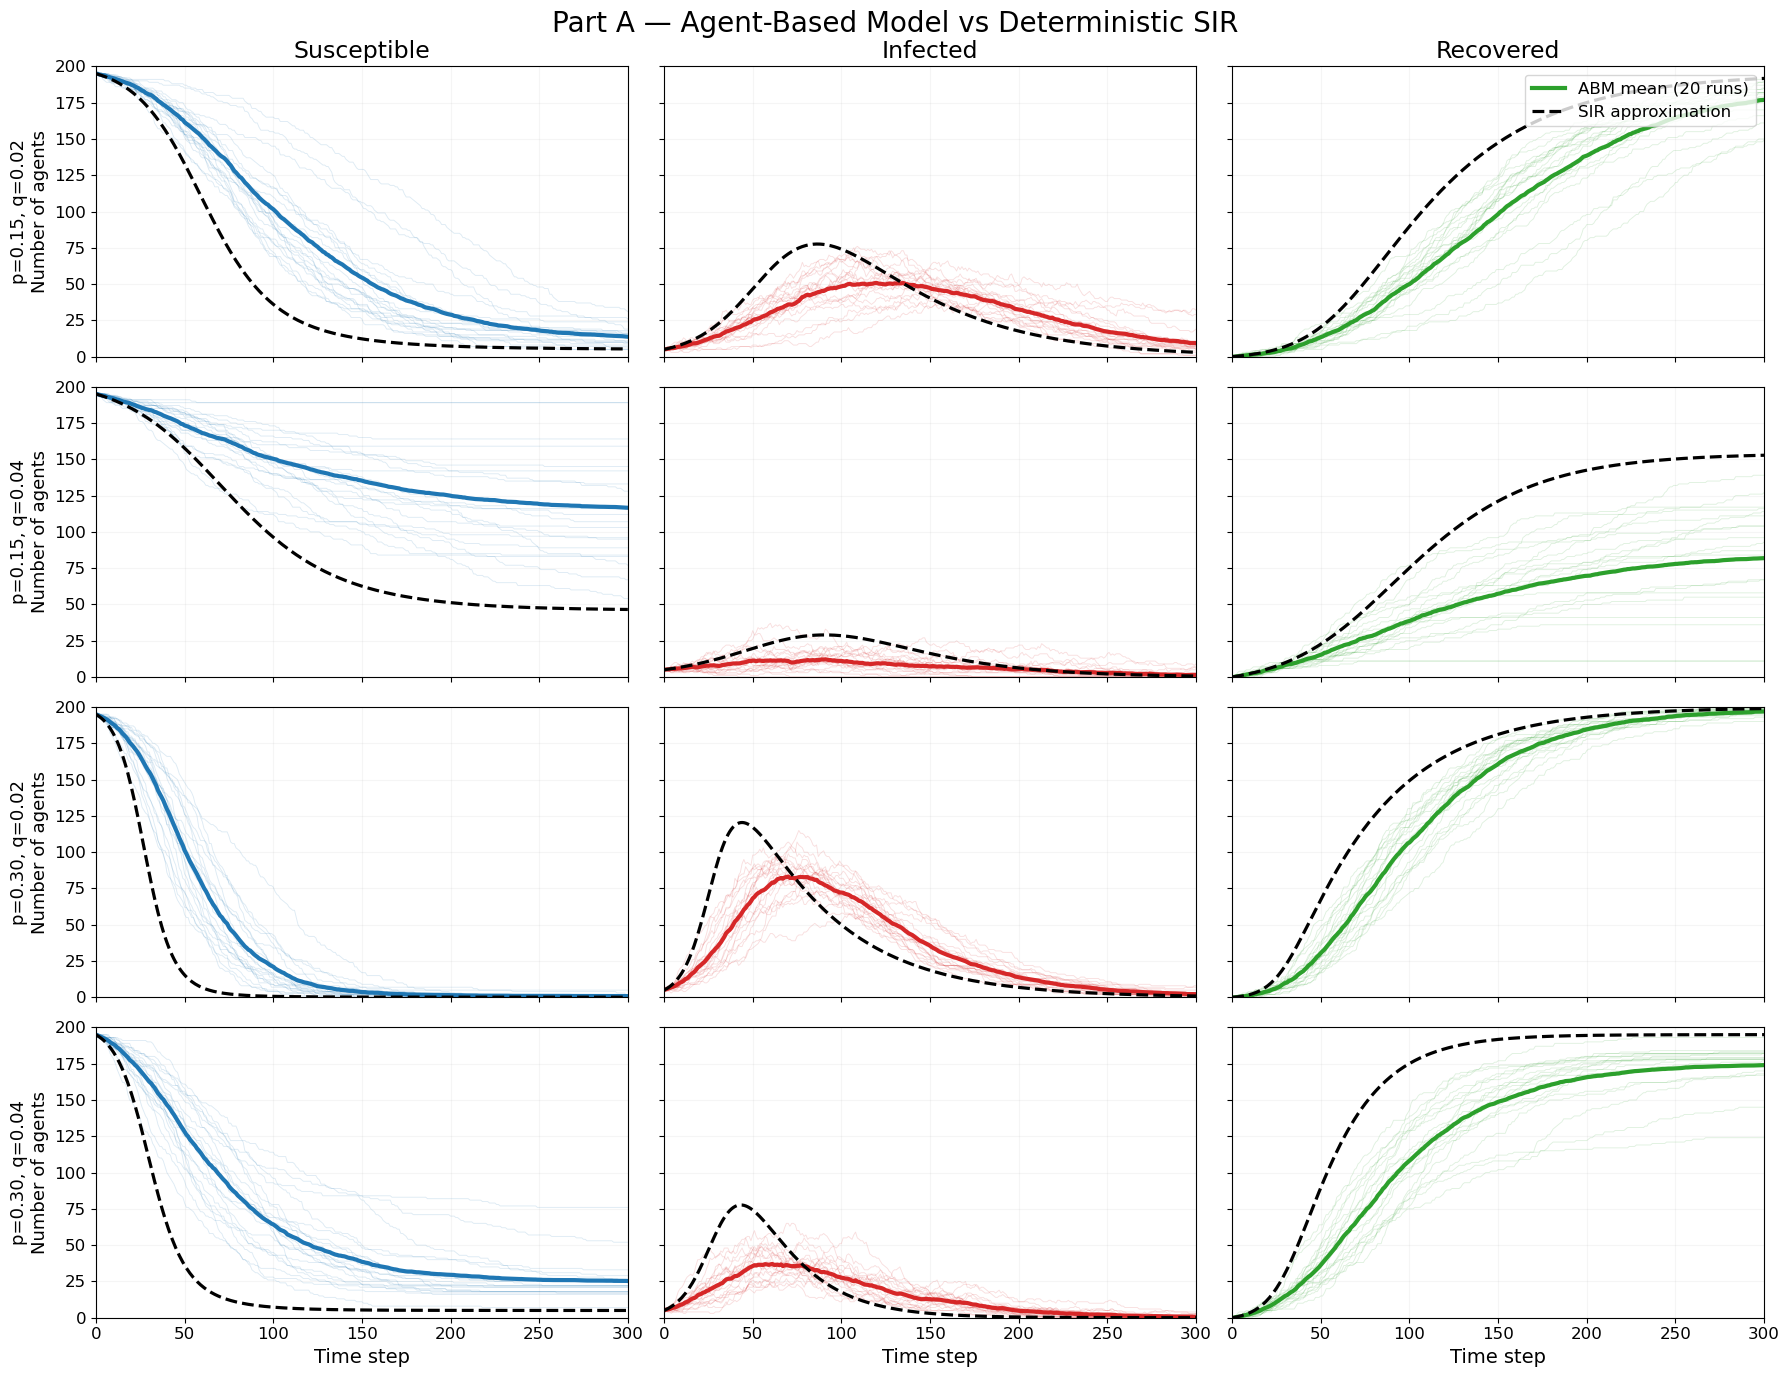

In [6]:
# ABM vs deterministic SIR
A_runs = runs.copy()

t = np.arange(N_STEPS + 1)

fig, axes = plt.subplots(
    4, 3, figsize=(18, 14),
    sharex=True, sharey=True
)

for row, (params, trajectories) in enumerate(A_runs.items()):
    p, q = params
    sir = simulate_sir(p, q)

    for state in (S, I, R):
        ax = axes[row, state]

        # Individual ABM runs
        for run in trajectories:
            ax.plot(
                t, run[:, state],
                color=COLORS[state],
                alpha=0.15, linewidth=0.65
            )

        # ABM mean
        ax.plot(
            t, trajectories[:, :, state].mean(axis=0),
            color=COLORS[state],
            linewidth=3,
            label="ABM mean (20 runs)"
        )

        # Deterministic SIR reference
        ax.plot(
            t, sir[:, state],
            color="black",
            linestyle="--",
            linewidth=2.3,
            label="SIR approximation"
        )

        if row == 0:
            ax.set_title(STATE_NAMES[state], fontsize=17)

        if state == S:
            ax.set_ylabel(
                f"p={p:.2f}, q={q:.2f}\nNumber of agents",
                fontsize=13
            )

        if row == 3:
            ax.set_xlabel("Time step", fontsize=14)

        ax.set_xlim(0, N_STEPS)
        ax.set_ylim(0, N_AGENTS)
        ax.tick_params(labelsize=12)
        ax.grid(alpha=0.12)

        if row == 0 and state == R:
            ax.legend(loc="upper right", fontsize=12)

fig.suptitle(
    "Part A — Agent-Based Model vs Deterministic SIR",
    fontsize=20
)

fig.tight_layout()
plt.show()


For the analysis we compute the following metrics

- **Peak infected**: $\max_t I(t)$
- **Time to peak**: $\argmax_t I(t)$
- **Ever infected**: $200-S(300)$
- **Extinction time**: first time when $I(t)=0$
- **Early extinction (our definition)**: extinction time $\le 100$


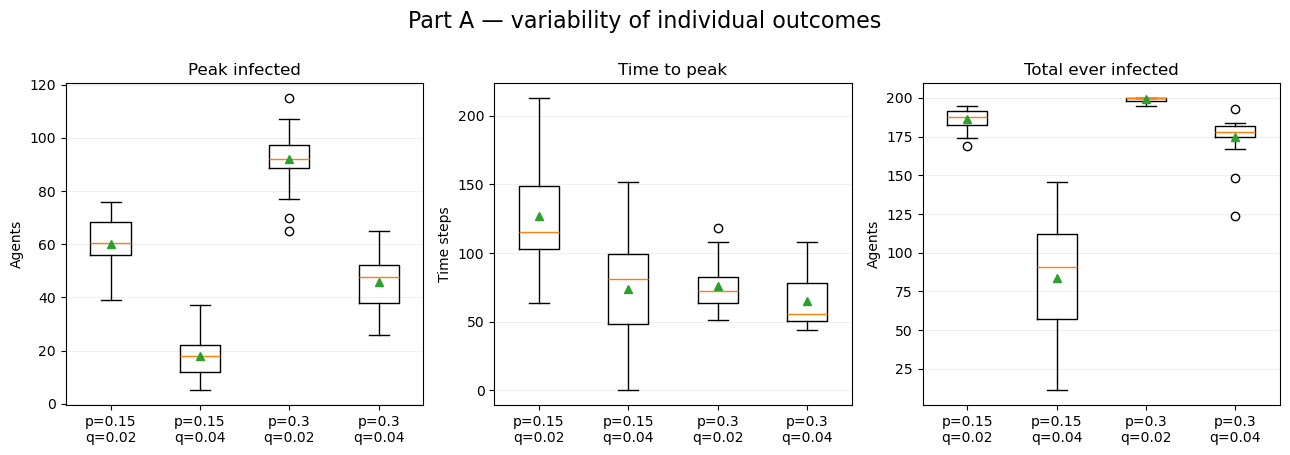

In [7]:
records = []
for (p, q), trajectories in runs.items():
    for j, trajectory in enumerate(trajectories):
        infected = trajectory[:, I]
        zero_times = np.flatnonzero(infected == 0)
        extinction_time = int(zero_times[0]) if len(zero_times) else np.nan
        records.append({
            "p": p, "q": q,
            "run": j + 1, "seed": SEEDS[j],
            "peak_infected": int(infected.max()),
            "time_to_peak": int(infected.argmax()),
            "ever_infected": int(N_AGENTS - trajectory[-1, S]),
            "extinction_time": extinction_time,
            "early_extinction_by_100": bool(len(zero_times) and zero_times[0] <= 100),
        })

metrics = pd.DataFrame(records)

summary = metrics.groupby(["p", "q"], sort=True).agg(
    peak_mean=("peak_infected", "mean"),
    peak_sd=("peak_infected", "std"),
    time_to_peak_mean=("time_to_peak", "mean"),
    time_to_peak_sd=("time_to_peak", "std"),
    ever_infected_mean=("ever_infected", "mean"),
    ever_infected_sd=("ever_infected", "std"),
    early_extinction_runs=("early_extinction_by_100", "sum"),
    runs=("run", "count"),
).round(2)

groups = list(runs.keys())
labels = [f"p={p:g}\nq={q:g}" for p, q in groups]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, (column, title) in zip(axes, [
    ("peak_infected", "Peak infected"),
    ("time_to_peak", "Time to peak"),
    ("ever_infected", "Total ever infected"),
]):
    values = [
        metrics.loc[(metrics.p == p) & (metrics.q == q), column].to_numpy()
        for p, q in groups
    ]
    ax.boxplot(values, showmeans=True)
    ax.set_xticks(range(1, len(labels) + 1), labels)
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.18)
    ax.set_ylabel("Agents" if column != "time_to_peak" else "Time steps")

fig.suptitle("Part A — variability of individual outcomes", y=1.0, fontsize=16)
fig.tight_layout()
plt.show()

In [8]:
summary

peak_mean  peak_sd  time_to_peak_mean  time_to_peak_sd  \
p    q                                                              
0.15 0.02      60.00    11.57             126.95            37.10   
     0.04      17.85     7.91              73.85            42.03   
0.30 0.02      91.90    11.72              75.80            18.42   
     0.04      45.85    10.28              65.15            18.87   

           ever_infected_mean  ever_infected_sd  early_extinction_runs  runs  
p    q                                                                        
0.15 0.02              186.25              7.20                      0    20  
     0.04               83.40             38.71                      2    20  
0.30 0.02              199.15              1.31                      0    20  
     0.04              174.70             14.79                      0    20

## Part A: Results and Discussion

We simulated an agent-based epidemic model with 200 agents on a 20 * 20 grid for 300 time steps. For each combination of transmission probability \(p\) and recovery probability \(q\), we performed 20 independent simulations using different random seeds. We summarize our results via the Table below:

| p | q | Mean peak infected | Mean time to peak | Mean ever infected by step 300 |
|---|---|---:|---:|---:|
| 0.15 | 0.02 | 60.00 | 126.95 | 186.25 |
| 0.15 | 0.04 | 17.85 | 73.85 | 83.40 |
| 0.30 | 0.02 | 91.90 | 75.80 | 199.15 |
| 0.30 | 0.04 | 45.85 | 65.15 | 174.70 |


**Effect of transmission probability.** Increasing \(p\), while keeping \(q\) fixed, produces a higher and earlier `infection peak` and increases the `total number of agents infected` during the simulation. This occurs because susceptible agents sharing a cell with infectious agents have a greater probability of becoming infected, accelerating epidemic spread.


**Effect of recovery probability.** Increasing \(q\) decreases the average `infection peak` and the `total number of infections`. Faster recovery reduces the time during which infected agents can transmit the disease, limiting opportunities for additional infections.

**Stochastic variability.** Individual simulation trajectories differ because `initial positions`, `movement`, `transmission`, and `recovery` are stochastic. The magnitude of variability depends on both the parameter setting and the metric. For example, when \(p=0.15\) and \(q=0.04\), the standard deviation of `total infections` is much larger than the setting where \(p=0.30\) and \(q=0.02\). 

**Early extinction.** We define early extinction as reaching zero infected agents by step 100. Only 2 of the 80 simulations experienced early extinction, both under \(p=0.15\) and \(q=0.04\). This suggests that early outbreak termination is possible, particularly when transmission is relatively weak and recovery is relatively fast, but it is uncommon under our tested settings.

**Comparison with SIR.** The average agent-based trajectories resemble the SIR model, as shown by the figure above. However, unlike a deterministic SIR model, the agent-based model explicitly represents spatial encounters and stochastic transitions. Therefore, it presents a more detailed view of epidemic transitions than the SIR model's global view.

# HW 2 — Part B: Extending the Model: Social Distancing and Interventions

## B-i: Introduce social distancing measures

In [9]:
def simulate_abm(p: float, q: float, seed: int, n_steps: int = N_STEPS, m: float = 1.0, avoidance: bool = False) :
    rng = np.random.default_rng(seed)

    # Init agent positions
    positions = rng.integers(0, GRID_SIZE, size=(N_AGENTS, 2))

    # Init agent states
    states = np.full(N_AGENTS, S, dtype=np.int8)
    initial_infected = rng.choice(N_AGENTS, size=5, replace=False)
    states[initial_infected] = I

    # Init history book to record past states
    history = np.zeros((n_steps + 1, 3), dtype=int)
    history[0] = np.bincount(states, minlength=3) # t = 0

    for t in range(1, n_steps + 1):
        # Move toward a direction
        chosen = rng.integers(0, len(DIRECTIONS), size=N_AGENTS)

        if avoidance:
            infected_cell_ids = positions[states == I, 0] * GRID_SIZE + positions[states == I, 1]
            occupied_by_infected = np.zeros(GRID_SIZE * GRID_SIZE, dtype=bool)
            occupied_by_infected[infected_cell_ids] = True

            for agent in np.flatnonzero(states == S):
                possible_positions = np.clip(positions[agent] + DIRECTIONS, 0, GRID_SIZE - 1)
                possible_cell_ids = possible_positions[:, 0] * GRID_SIZE + possible_positions[:, 1]
                safe_actions = np.flatnonzero(~occupied_by_infected[possible_cell_ids])
                if len(safe_actions):
                    chosen[agent] = rng.choice(safe_actions)

        if m < 1.0:
            # agent might stay in the same place
            can_move = rng.random(N_AGENTS) < m
            chosen[~can_move] = 0

        positions = np.clip(positions + DIRECTIONS[chosen], 0, GRID_SIZE - 1)

        # Transmission 
        cell_ids = positions[:, 0] * GRID_SIZE + positions[:, 1]
        infected_per_cell = np.bincount(cell_ids[states == I], minlength=GRID_SIZE * GRID_SIZE)
        at_risk = (states == S) & (infected_per_cell[cell_ids] > 0)
        new_infections = at_risk & (rng.random(N_AGENTS) < p)

        # Recovered people
        new_recoveries = (states == I) & (rng.random(N_AGENTS) < q)

        # Record updates
        states[new_recoveries] = R
        states[new_infections] = I
        history[t] = np.bincount(states, minlength=3)

    return history


In [10]:
P_VALUES, Q_VALUES = 0.3, 0.02
M_VALUES = [1.0, 0.6, 0.3, 0.1]

# reduced movement exp
m_runs = {}
for m in M_VALUES:
    m_runs[m] = np.stack([simulate_abm(P_VALUES, Q_VALUES, seed, m=m) for seed in SEEDS])

# avoidance exp
avoidance_runs = np.stack([simulate_abm(P_VALUES, Q_VALUES, seed, avoidance=True) for seed in SEEDS])

B_runs = {"Baseline (m=1.0)": m_runs[1.0], "Reduced (m=0.3)": m_runs[0.3], "Avoidance": avoidance_runs}

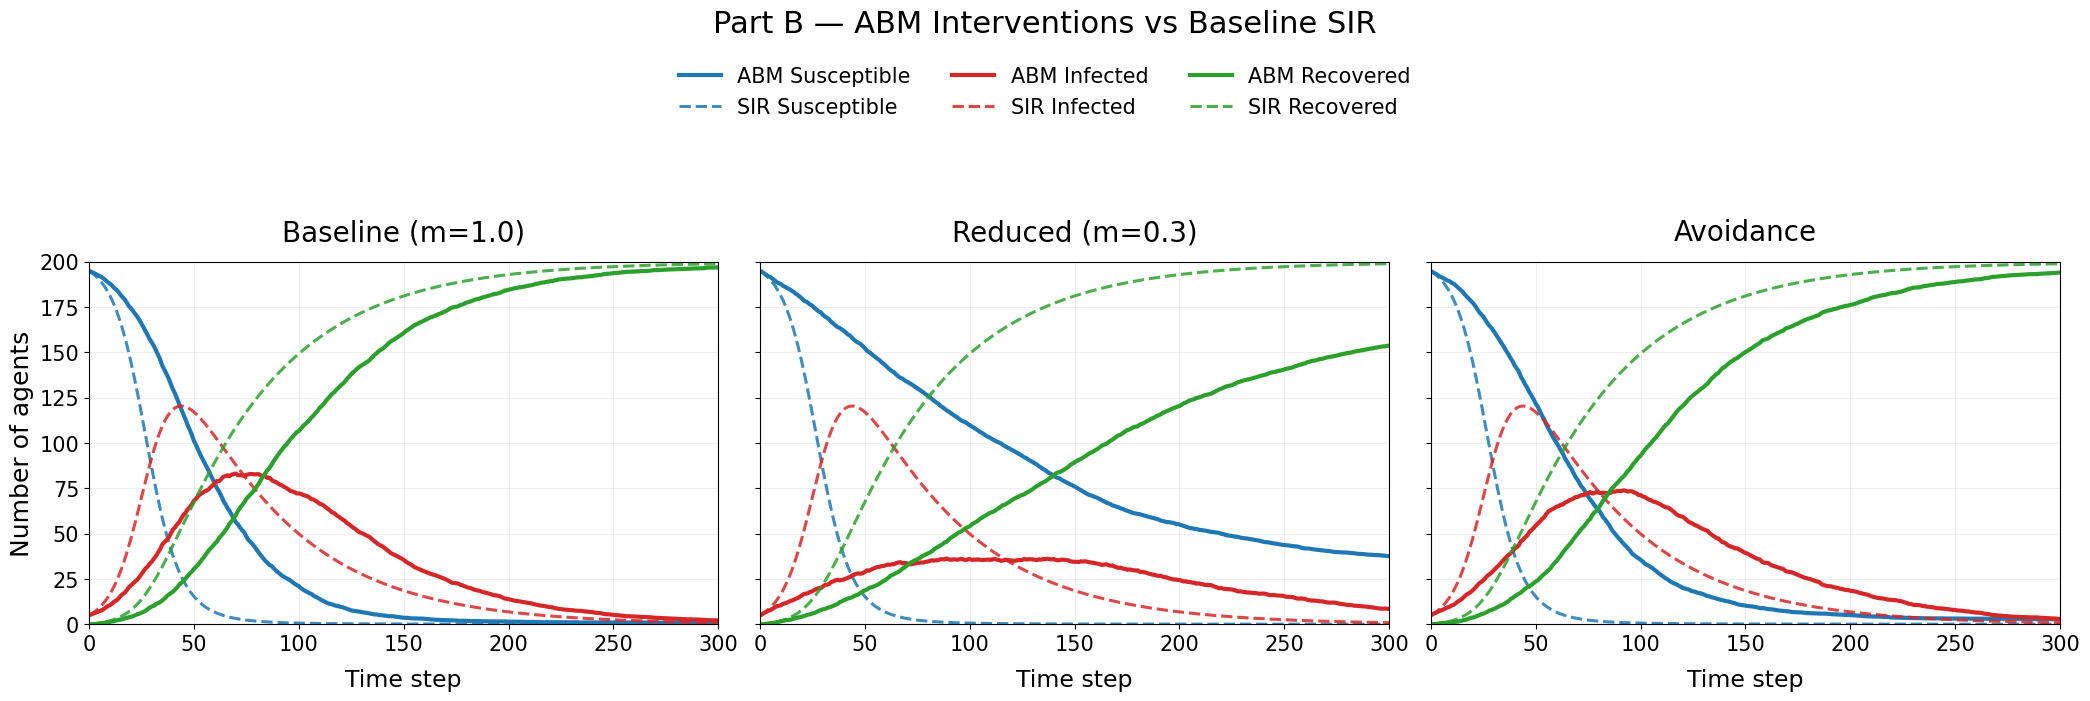

In [11]:
t = np.arange(N_STEPS + 1)
sir_baseline = simulate_sir(p=0.3, q=0.02)

fig, axes = plt.subplots(
    1, 3, figsize=(21, 7),
    sharex=True, sharey=True
)

for ax, (name, trajectories) in zip(axes, B_runs.items()):
    mean_trajectory = trajectories.mean(axis=0)

    for state in (S, I, R):

        # ABM mean
        ax.plot(
            t, mean_trajectory[:, state],
            label=f"ABM {STATE_NAMES[state]}",
            color=COLORS[state],
            linewidth=3
        )

        # Same SIR baseline for all interventions
        ax.plot(
            t, sir_baseline[:, state],
            label=f"SIR {STATE_NAMES[state]}",
            color=COLORS[state],
            linestyle="--",
            linewidth=2.2,
            alpha=0.85
        )

    ax.set_title(name, fontsize=20, pad=15)
    ax.set_xlabel("Time step", fontsize=17, labelpad=10)
    ax.set_xlim(0, N_STEPS)
    ax.set_ylim(0, N_AGENTS)
    ax.tick_params(axis="both", labelsize=15)
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Number of agents", fontsize=18)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles, labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.94),
    ncol=3,
    fontsize=15,
    frameon=False
)

fig.suptitle(
    "Part B — ABM Interventions vs Baseline SIR",
    fontsize=22,
    y=0.995
)

fig.tight_layout(rect=[0, 0, 1, 0.78])
plt.show()

In [12]:
peak_results = []

for name, runs in B_runs.items():
    peaks = runs[:, :, 1].max(axis=1)
    peak_results.append({
        "Setting": name,
        "Mean Peak": peaks.mean(),
        "Std Peak": peaks.std(ddof=1),
    })

peak_df = pd.DataFrame(peak_results)
display(peak_df)


,Setting,Mean Peak,Std Peak
0,Baseline (m=1.0),91.9,11.715487
1,Reduced (m=0.3),45.3,10.162366
2,Avoidance,80.9,8.849026


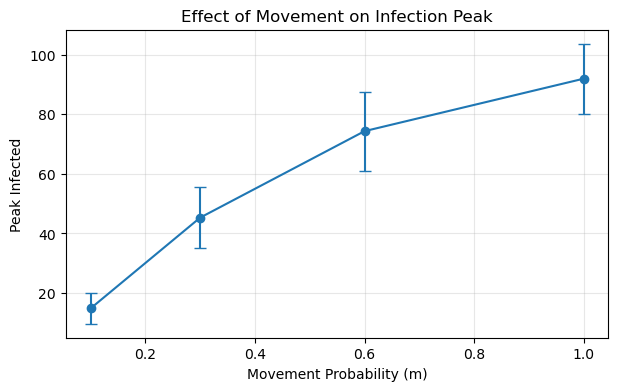

In [13]:
peak_results_m = []

for m in M_VALUES:
    peaks = m_runs[m][:, :, 1].max(axis=1)
    peak_results_m.append({
        "m": m,
        "Mean Peak": peaks.mean(),
        "Std Peak": peaks.std(ddof=1)
    })

peak_m_df = pd.DataFrame(peak_results_m).sort_values("m")

plt.figure(figsize=(7, 4))

plt.errorbar(
    peak_m_df["m"],
    peak_m_df["Mean Peak"],
    yerr=peak_m_df["Std Peak"],
    marker="o",
    capsize=4
)

plt.xlabel("Movement Probability (m)")
plt.ylabel("Peak Infected")
plt.title("Effect of Movement on Infection Peak")
plt.grid(alpha=0.3)
plt.show()

## Discussion (i)

1. **How we implement Reduced Movement:** We modify the movement function so that each agent performs a random walk with probability \(m\) and otherwise stays in place.

2. **How we implement Avoidance:** We modify the movement function so that susceptible agents prefer to move to neighboring cells without infected agents whenever possible.

3. **Factors controlling the infection peak:** As demonstrated in Part A, both transmission probability $p$ and recovery probability $q$ influence the maximum number of simultaneously infected agents. In Part B, we additionally observe that movement restrictions and avoidance can reduce this peak. For example, the mean peak decreases from 91.90 agents under the baseline setting to 45.30 under reduced movement (m=0.3) and 80.90 under avoidance.

4. **Implications for healthcare capacity**: A lower infection peak may reduce the risk of overwhelming healthcare resources by decreasing the maximum number of concurrent infections. Delaying the peak may also provide additional time for preparation. 

In [14]:
B_records = []
for name, trajectories in B_runs.items():
    for j, trajectory in enumerate(trajectories):
        infected = trajectory[:, I]
        zero_times = np.flatnonzero(infected == 0)
        extinction_time = int(zero_times[0]) if len(zero_times) else np.nan
        B_records.append({
            "intervention": name,
            "run": j + 1, "seed": SEEDS[j],
            "peak_infected": int(infected.max()),
            "time_to_peak": int(infected.argmax()),
            "ever_infected": int(N_AGENTS - trajectory[-1, S]),
            "extinction_time": extinction_time,
        })

B_metrics = pd.DataFrame(B_records)

B_summary = B_metrics.groupby("intervention", sort=False).agg(
    peak_mean=("peak_infected", "mean"),
    peak_sd=("peak_infected", "std"),
    time_to_peak_mean=("time_to_peak", "mean"),
    time_to_peak_sd=("time_to_peak", "std"),
    ever_infected_mean=("ever_infected", "mean"),
    ever_infected_sd=("ever_infected", "std"),
    extinction_mean_observed=("extinction_time", "mean"),
    observed_extinction_runs=("extinction_time", "count"),
    runs=("run", "count"),
).round(2)

B_summary

,peak_mean,peak_sd,time_to_peak_mean,time_to_peak_sd,ever_infected_mean,ever_infected_sd,extinction_mean_observed,observed_extinction_runs,runs
intervention,,,,,,,,,
Baseline (m=1.0),91.9,11.72,75.8,18.42,199.15,1.31,281.5,2,20
Reduced (m=0.3),45.3,10.16,112.7,44.99,162.30,25.74,NaN,0,20
Avoidance,80.9,8.85,86.3,18.97,197.10,2.59,297.5,2,20


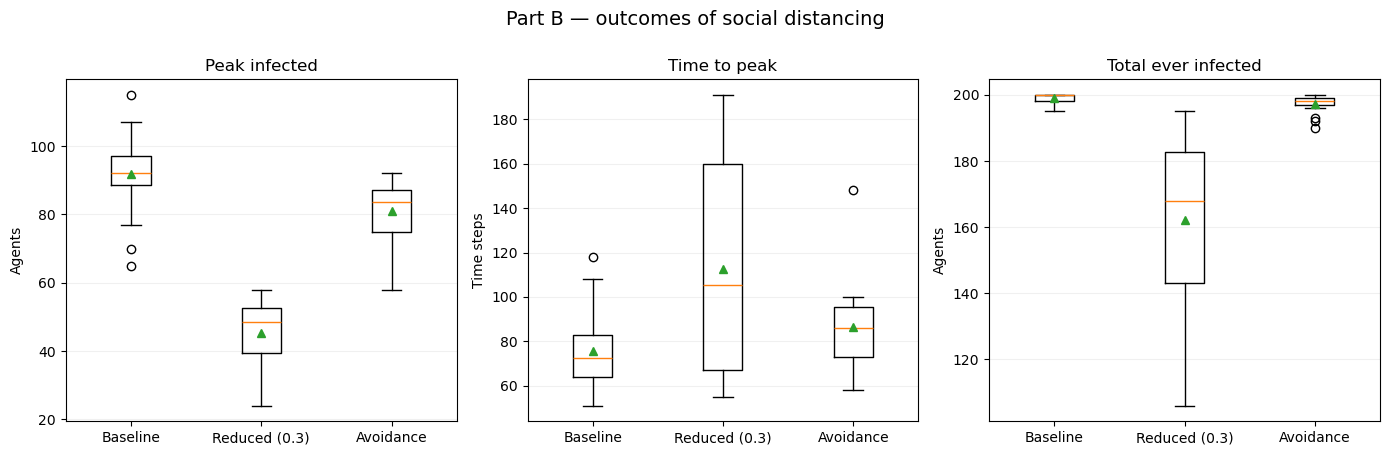

In [15]:
B_labels = list(B_runs.keys())
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, (column, title) in zip(axes, [("peak_infected", "Peak infected"), 
                                      ("time_to_peak", "Time to peak"), 
                                      ("ever_infected", "Total ever infected")]):
    values = [B_metrics.loc[B_metrics.intervention == name, column].to_numpy() for name in B_labels]
    ax.boxplot(values, showmeans=True)
    ax.set_xticks(range(1, len(B_labels) + 1), ["Baseline", "Reduced (0.3)", "Avoidance"])
    ax.set_title(title)
    ax.set_ylabel("Time steps" if column == "time_to_peak" else "Agents")
    ax.grid(axis="y", alpha=0.18)

fig.suptitle("Part B — outcomes of social distancing", y=1.0, fontsize=14)
fig.tight_layout()
plt.show()

## Discussion (ii)

**Compare the results:** We compare the baseline model, reduced movement (m=0.3), and avoidance using 20 independent simulations for each setting, with p=0.3 and q=0.02. The result is shown in Table above.

We find that 

1. **Infection peak and timing**: Both social distancing (reduced movement, and avoidance) reduce the average infection peak and delay its occurrence. 

2. **Total infections**: Reduced movement lowers the mean number of agents ever infected from 199.15 to 162.30. In comparison, avoidance only reduces this value to 197.10. These results suggest that reducing movement is more effective than the implemented avoidance strategy (at least this is the result from our simulations). 

3. **Time until extinction**: Extinction is observed in only 2 of 20 baseline runs, none of the reduced-movement runs, and 2 of the avoidance runs within 300 steps. This observation suggests that although social distancing reduces infection peaks, it may also allow low-level transmission to persist for a longer time. 

4. **Public health implications**: Our findings suggest that interventions reducing contact opportunities can substantially flatten epidemic curves and lower cumulative infections. This may help reduce pressure on healthcare systems during an outbreak. For example, the lockdown policy is really effective for COVID control in 2020.

In [16]:
m_records = []
for m, trajectories in m_runs.items():
    for j, trajectory in enumerate(trajectories):
        infected = trajectory[:, I]
        m_records.append({
            "m": m,
            "run": j + 1, "seed": SEEDS[j],
            "peak_infected": int(infected.max()),
            "time_to_peak": int(infected.argmax()),
            "ever_infected": int(N_AGENTS - trajectory[-1, S]),
        })

m_metrics = pd.DataFrame(m_records)
m_summary = m_metrics.groupby("m").agg(
    peak_mean=("peak_infected", "mean"),
    peak_sd=("peak_infected", "std"),
    time_to_peak_mean=("time_to_peak", "mean"),
    time_to_peak_sd=("time_to_peak", "std"),
    ever_infected_mean=("ever_infected", "mean"),
    runs=("run", "count"),
).round(2)

m_summary

,peak_mean,peak_sd,time_to_peak_mean,time_to_peak_sd,ever_infected_mean,runs
m,,,,,,
0.1,14.85,5.12,66.50,42.02,50.55,20
0.3,45.30,10.16,112.70,44.99,162.30,20
0.6,74.30,13.28,95.35,35.59,194.20,20
1.0,91.90,11.72,75.80,18.42,199.15,20


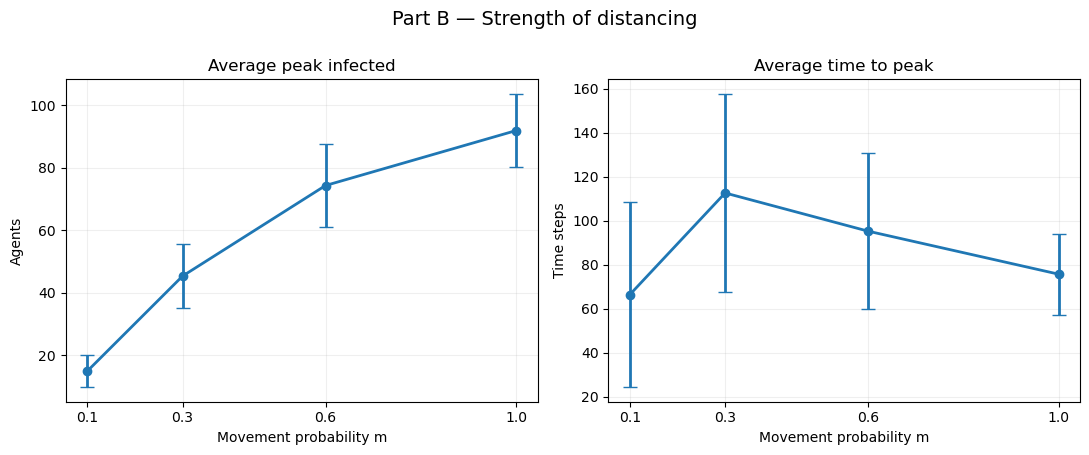

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, mean_col, sd_col, title, y_label in zip(axes, ["peak_mean", "time_to_peak_mean"], 
                                                ["peak_sd", "time_to_peak_sd"],
                                                ["Average peak infected", "Average time to peak"],
                                                ["Agents", "Time steps"]
                                                ):
    ax.errorbar(m_summary.index, m_summary[mean_col], yerr=m_summary[sd_col], marker="o", capsize=5, linewidth=2)
    ax.set(xlabel="Movement probability m", ylabel=y_label, title=title, xticks=sorted(M_VALUES))
    ax.grid(alpha=0.2)

fig.suptitle("Part B — Strength of distancing", y=1.0, fontsize=14)
fig.tight_layout()
plt.show()

## Discussion (iii)

To investigate how distancing strength affects epidemic dynamics, we vary the movement parameter $m$ across 1.0, 0.6, 0.3, and 0.1.

The results show a clear relationship between movement and infection peak size. The mean peak number of infected agents decreases as $m$ decreases. The mean number of agents ever infected also decreases substantially. This suggests that stricter movement restrictions can effectively suppress transmission.

Interestingly, the time to peak does not change monotonically with movement probability. It decreases when $m$ changes from 0.3 to 0.1. One possible explanation is that extremely limited movement prevents infections from spreading widely across the population. As a result, some outbreaks may remain localized and reach relatively small peaks early, rather than developing into large, delayed epidemics. 

Overall, our results demonstrate that stricter social distancing consistently reduces the infection peak, but its effect on peak timing might be more complex.